# 05 · Rede neural para classificar manchetes (LSTM e GRU)

Entrega da Etapa 4 (29/10). A tarefa é a mesma do notebook 03: classificar a manchete como **boa, neutra ou ruim para o acionista**. A diferença é que, agora, nós **treinamos** o classificador.

**Por que não treinar com as nossas 200 manchetes?** Elas são a única base revisada por nós, então são o nosso teste. Se fossem usadas no treino, a avaliação ficaria inflada. Também não usamos as manchetes rotuladas automaticamente pelo FinBERT: um modelo treinado nesses rótulos aprenderia os erros do FinBERT, e o teto seria a acurácia dele (56%).

**Dados de treino**, todos públicos:

| base | textos | rótulo | licença |
|---|---|---|---|
| `lucas-leme/Sentiments-FinBERT-PT-BR` | 503 notícias financeiras brasileiras | 3 anotadores humanos, critério "retorno positivo, negativo ou neutro" | Apache 2.0 |
| `heitorrosa/financial-sentiment-pt` | ~60 mil manchetes e frases financeiras | bases em inglês (Financial PhraseBank, manchetes, tweets) traduzidas por modelo, com nota de qualidade da tradução | GPL-3.0 |

O critério das duas é próximo do nosso: o impacto para o investidor, e não o tom da frase.

**Modelos** (cada um vem de uma aula):

1. TF-IDF + Regressão Logística: linha de base clássica (aula 4);
2. Embedding + **BiLSTM** (aula 10);
3. Embedding + **GRU** (aula 10);
4. a BiLSTM com **ajuste fino** nas notícias brasileiras (transferência de aprendizado).

Todos são avaliados nas 200 manchetes de `data/teste_revisao.csv` e comparados ao FinBERT-PT-BR do notebook 03.

**Como rodar:** abra no VS Code ou no Jupyter e execute tudo, a partir da pasta `notebooks/`. A primeira execução baixa as bases (~30 MB) para `data/raw/`. Em CPU, o treino leva poucos minutos.

In [1]:
import os
import random
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"  # resultados repetíveis em CPU

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

sys.path.insert(0, "../src")
from preprocessamento import limpa

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)

DADOS = Path("../data")
RAW = DADOS / "raw"
RAW.mkdir(parents=True, exist_ok=True)
SAIDA = Path("../Entregas/30-10-2026")
SAIDA.mkdir(parents=True, exist_ok=True)

ROTULOS = ["boa", "neutra", "ruim"]
pd.set_option("display.max_colwidth", 120)

## Dados de treino

In [2]:
def baixa(url, arq):
    if not arq.exists():
        print(f"Baixando {url}")
        import urllib.request
        urllib.request.urlretrieve(url, arq)
    return arq


HF = "https://huggingface.co/datasets"
arq_lucas = baixa(f"{HF}/lucas-leme/Sentiments-FinBERT-PT-BR/resolve/main/sentiments.csv", RAW / "finbert_ptbr_sentiments.csv")
arq_heitor = baixa(f"{HF}/heitorrosa/financial-sentiment-pt/resolve/main/final.jsonl", RAW / "financial_sentiment_pt.jsonl")

lucas = pd.read_csv(arq_lucas)
lucas = lucas[lucas["sentiment"].isin(["Positivo", "Neutro", "Negativo"])]
lucas = pd.DataFrame({
    "texto": lucas["text"],
    "rotulo": lucas["sentiment"].map({"Positivo": "boa", "Neutro": "neutra", "Negativo": "ruim"}),
    "base": "FinBERT-PT-BR (humano)",
})

heitor = pd.read_json(arq_heitor, lines=True)
print(f"Tradução com nota de qualidade: média {heitor['quality'].mean():.2f}")
heitor = heitor[heitor["quality"] >= 0.6]  # descarta as traduções piores
heitor = pd.DataFrame({
    "texto": heitor["translated"],
    "rotulo": heitor["sentiment"].map({"positive": "boa", "neutral": "neutra", "negative": "ruim"}),
    "base": "financial-sentiment-pt (traduzido)",
}).dropna()

treino_total = pd.concat([lucas, heitor], ignore_index=True)
treino_total["limpo"] = treino_total["texto"].apply(limpa)
treino_total = treino_total[treino_total["limpo"].str.len() > 0].drop_duplicates("limpo").reset_index(drop=True)
pd.crosstab(treino_total["base"], treino_total["rotulo"], margins=True)

Tradução com nota de qualidade: média 0.69


rotulo,boa,neutra,ruim,All
base,,,,
FinBERT-PT-BR (humano),160,140,203,503
financial-sentiment-pt (traduzido),20497,13358,12571,46426
All,20657,13498,12774,46929


## Base de teste

As 200 manchetes revisadas. Retiramos do treino qualquer texto igual a uma manchete do teste (depois da limpeza), para garantir que o teste é inédito.

In [3]:
teste = pd.read_csv(DADOS / "teste_revisao.csv")
teste = teste[teste["rotulo"].isin(ROTULOS)].reset_index(drop=True)
teste["limpo"] = teste["manchete"].apply(limpa)

antes = len(treino_total)
treino_total = treino_total[~treino_total["limpo"].isin(set(teste["limpo"]))].reset_index(drop=True)
print(f"Removidos do treino por coincidir com o teste: {antes - len(treino_total)}")
print(f"Teste: {len(teste)} manchetes")
teste["rotulo"].value_counts().reindex(ROTULOS).to_frame("manchetes").T

Removidos do treino por coincidir com o teste: 0
Teste: 200 manchetes


rotulo,boa,neutra,ruim
manchetes,76,96,28


## Pré-processamento

Função `limpa` em `src/preprocessamento.py` (aula 2): minúsculas, sem URLs e pontuação, e números, valores, percentuais e tickers trocados por marcadores. Não removemos stopwords: em sentimento, "não", "mas" e "após" importam.

In [4]:
for t in teste["manchete"].head(4):
    print(f"{t}\n  -> {limpa(t)}\n")

comprimentos = treino_total["limpo"].str.split().str.len()
print(f"Tokens por texto no treino: mediana {comprimentos.median():.0f}, 95% até {comprimentos.quantile(.95):.0f}")

Santander Brasil (SANB11) aprova JCP de R$ 0,40 por unit
  -> santander brasil <ticker> aprova jcp de <valor> por unit

Banco do Brasil (BBAS3) Antecipa R$ 197 Milhões em JCP; Veja Quem Recebe e Quando Cai na Conta
  -> banco do brasil <ticker> antecipa <valor> em jcp veja quem recebe e quando cai na conta

Santander prossegue com OPA voluntária e pede à CVM registro de emissor estrangeiro
  -> santander prossegue com opa voluntária e pede à cvm registro de emissor estrangeiro

Embraer (EMBJ3): comprar agora ou esperar uma queda?
  -> embraer <ticker> comprar agora ou esperar uma queda

Tokens por texto no treino: mediana 17, 95% até 53


## Treino e validação

Separamos 10% do treino para validação (parada antecipada e escolha da época), estratificado por rótulo. O teste não entra em nenhuma decisão de treino.

In [5]:
treino, valid = train_test_split(treino_total, test_size=0.1, stratify=treino_total["rotulo"], random_state=SEMENTE)
print(f"Treino: {len(treino)} · Validação: {len(valid)} · Teste: {len(teste)}")

indice = {r: i for i, r in enumerate(ROTULOS)}
y_treino, y_valid, y_teste = (d["rotulo"].map(indice).to_numpy() for d in (treino, valid, teste))

# Classes desbalanceadas: o peso de cada classe é inverso à sua frequência
pesos = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=y_treino)))
print("Pesos por classe:", {ROTULOS[k]: round(float(v), 2) for k, v in pesos.items()})

Treino: 42236 · Validação: 4693 · Teste: 200
Pesos por classe: {'boa': 0.76, 'neutra': 1.16, 'ruim': 1.22}


## 1 · Linha de base: TF-IDF + Regressão Logística

Treinamos duas vezes: só com as 503 notícias rotuladas por humanos e com as duas bases juntas. Isso mostra quanto o volume de dados traduzidos ajuda.

In [6]:
def avalia(nome, previsto, y=y_teste):
    return {"modelo": nome, "acurácia": accuracy_score(y, previsto), "F1 macro": f1_score(y, previsto, average="macro"),
            **{f"F1 {r}": f for r, f in zip(ROTULOS, f1_score(y, previsto, average=None, labels=range(3)))}}


def tfidf_lr(dados):
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    lr = LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0)
    lr.fit(tfidf.fit_transform(dados["limpo"]), dados["rotulo"].map(indice))
    return lambda textos: lr.predict(tfidf.transform(textos))


tabela = []
so_humano = treino[treino["base"].str.contains("humano")]
for nome, dados in [("TF-IDF + LR (só 503 humanos)", so_humano), ("TF-IDF + LR (todas as bases)", treino)]:
    prev = tfidf_lr(dados)(teste["limpo"])
    tabela.append(avalia(nome, prev))
    teste[nome] = [ROTULOS[i] for i in prev]
pd.DataFrame(tabela).set_index("modelo").round(3)

,acurácia,F1 macro,F1 boa,F1 neutra,F1 ruim
modelo,,,,,
TF-IDF + LR (só 503 humanos),0.385,0.361,0.459,0.439,0.186
TF-IDF + LR (todas as bases),0.520,0.488,0.381,0.617,0.467


## 2 e 3 · Redes neurais: BiLSTM e GRU

Arquitetura:

```
texto -> TextVectorization -> Embedding(128) -> BiLSTM(64) ou GRU(64) -> Dropout(0,3) -> Dense(3, softmax)
```

- `TextVectorization` faz o papel do `Tokenizer` + `pad_sequences` do Keras antigo: cria o vocabulário (20 mil palavras mais frequentes do treino) e transforma cada texto numa sequência de 40 índices.
- A camada `Embedding` aprende um vetor denso por palavra (aula 6), do zero, junto com a tarefa.
- A **BiLSTM** lê a manchete nos dois sentidos, então "lucro sobe, **mas** ação cai" é vista com o contexto da esquerda e da direita. A **GRU** tem menos parâmetros (2 portas em vez de 3) e lê num sentido só.
- Paramos quando o F1 na validação para de subir por 2 épocas (`EarlyStopping`) e ficamos com os pesos da melhor época.

In [7]:
MAX_TOKENS, MAX_LEN = 20_000, 40

vetorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN,
                                       standardize=None, split="whitespace")
vetorizador.adapt(treino["limpo"].to_numpy())
print(f"Vocabulário: {vetorizador.vocabulary_size()} palavras · exemplos: {[str(p) for p in vetorizador.get_vocabulary()[2:12]]}")

X_treino, X_valid, X_teste = (vetorizador(d["limpo"].to_numpy()) for d in (treino, valid, teste))

# Palavras do teste que a rede nunca viu no treino viram o token [UNK] e não carregam informação
vocab = set(vetorizador.get_vocabulary())
palavras_teste = teste["limpo"].str.split().explode()
fora = palavras_teste[~palavras_teste.isin(vocab)]
print(f"{len(fora) / len(palavras_teste):.1%} das palavras do teste estão fora do vocabulário. Mais frequentes:")
print(fora.value_counts().head(15).to_dict())


class F1Macro(keras.callbacks.Callback):
    """Calcula o F1 macro na validação a cada época (o Keras só traz acurácia)."""
    def on_epoch_end(self, epoch, logs=None):
        prev = self.model.predict(X_valid, verbose=0).argmax(1)
        logs["val_f1"] = f1_score(y_valid, prev, average="macro")


def cria_modelo(tipo):
    recorrente = layers.Bidirectional(layers.LSTM(64)) if tipo == "BiLSTM" else layers.GRU(64)
    modelo = keras.Sequential([
        keras.Input(shape=(MAX_LEN,), dtype="int64"),
        layers.Embedding(MAX_TOKENS, 128, mask_zero=True),
        recorrente,
        layers.Dropout(0.3),
        layers.Dense(3, activation="softmax"),
    ], name=tipo)
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


def treina(tipo):
    tf.random.set_seed(SEMENTE)
    modelo = cria_modelo(tipo)
    hist = modelo.fit(
        X_treino, y_treino, validation_data=(X_valid, y_valid), epochs=10, batch_size=128, class_weight=pesos,
        callbacks=[F1Macro(), keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=2,
                                                            restore_best_weights=True)],
        verbose=2,
    )
    return modelo, pd.DataFrame(hist.history)


modelos, historicos = {}, {}
for tipo in ["BiLSTM", "GRU"]:
    print(f"\n=== {tipo} ===")
    modelos[tipo], historicos[tipo] = treina(tipo)
modelos["BiLSTM"].summary()

Vocabulário: 20000 palavras · exemplos: ['de', 'a', '<num>', 'o', 'em', 'e', 'da', 'para', 'que', 'do']


12.3% das palavras do teste estão fora do vocabulário. Mais frequentes:
{'prio': 12, 'sabesp': 11, 'equatorial': 11, 'weg': 11, 'localiza': 11, 'btg': 10, 'pactual': 8, 'suzano': 7, 'raia': 5, 'drogasil': 5, 'rd': 5, 'bradsaúde': 5, 'opa': 3, 'rali': 3, 'proventos': 3}

=== BiLSTM ===
Epoch 1/10


330/330 - 38s - 116ms/step - accuracy: 0.5640 - loss: 0.9049 - val_accuracy: 0.6128 - val_loss: 0.8481 - val_f1: 0.6100


Epoch 2/10


330/330 - 31s - 93ms/step - accuracy: 0.7017 - loss: 0.6816 - val_accuracy: 0.6124 - val_loss: 0.8878 - val_f1: 0.6083


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 128)        │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,977,611 (30.43 MB)

 Trainable params: 2,659,203 (10.14 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,318,408 (20.29 MB)

### Curvas de treino

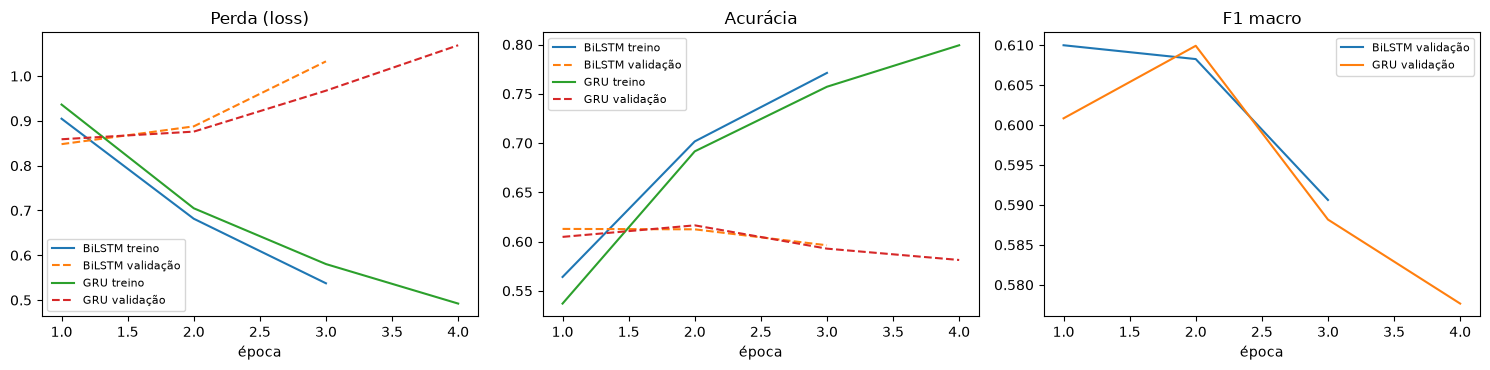

In [8]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8))
for tipo, h in historicos.items():
    epocas = range(1, len(h) + 1)
    eixos[0].plot(epocas, h["loss"], label=f"{tipo} treino")
    eixos[0].plot(epocas, h["val_loss"], "--", label=f"{tipo} validação")
    eixos[1].plot(epocas, h["accuracy"], label=f"{tipo} treino")
    eixos[1].plot(epocas, h["val_accuracy"], "--", label=f"{tipo} validação")
    eixos[2].plot(epocas, h["val_f1"], label=f"{tipo} validação")
for ax, titulo in zip(eixos, ["Perda (loss)", "Acurácia", "F1 macro"]):
    ax.set_title(titulo)
    ax.set_xlabel("época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Ajuste fino nas notícias brasileiras

Mais de 99% do treino é texto traduzido do inglês. Para aproximar a rede do nosso domínio, continuamos o treino da BiLSTM **só com as notícias brasileiras rotuladas por humanos**, com taxa de aprendizado 10 vezes menor, para não apagar o que ela já aprendeu. É a mesma ideia de transferência de aprendizado do fine-tuning de Transformers, que é a próxima etapa do projeto. A validação aqui são as notícias brasileiras que caíram na validação.

In [9]:
humanos_treino = treino["base"].str.contains("humano").to_numpy()
humanos_valid = valid["base"].str.contains("humano").to_numpy()
print(f"Ajuste fino com {humanos_treino.sum()} notícias, validação com {humanos_valid.sum()}")

tf.random.set_seed(SEMENTE)
ajustado = keras.models.clone_model(modelos["BiLSTM"])
ajustado.set_weights(modelos["BiLSTM"].get_weights())
ajustado.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
ajustado.fit(
    tf.boolean_mask(X_treino, humanos_treino), y_treino[humanos_treino],
    validation_data=(tf.boolean_mask(X_valid, humanos_valid), y_valid[humanos_valid]),
    epochs=20, batch_size=16, class_weight=pesos, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)
modelos["BiLSTM + ajuste fino"] = ajustado

Ajuste fino com 453 notícias, validação com 50


## Avaliação no teste (200 manchetes revisadas)

A linha do FinBERT-PT-BR vem do notebook 03 (`Entregas/27-10-2026/resultado_sentimentos.csv`), nas mesmas 200 manchetes. Como as classes são desbalanceadas (96 neutras, 76 boas, 28 ruins), o **F1 macro** é a métrica principal: ele dá o mesmo peso às três classes, então um modelo que chuta "neutra" sempre não vai bem.

In [10]:
for tipo, modelo in modelos.items():
    prev = modelo.predict(X_teste, verbose=0).argmax(1)
    tabela.append(avalia(tipo, prev))
    teste[tipo] = [ROTULOS[i] for i in prev]

finbert = pd.read_csv("../Entregas/27-10-2026/resultado_sentimentos.csv").set_index("id")
teste["FinBERT-PT-BR"] = teste["id"].map(finbert["previsto"])
tabela.append(avalia("FinBERT-PT-BR (notebook 03, sem treino)", teste["FinBERT-PT-BR"].map(indice)))

comparacao = pd.DataFrame(tabela).set_index("modelo").round(3)
comparacao

,acurácia,F1 macro,F1 boa,F1 neutra,F1 ruim
modelo,,,,,
TF-IDF + LR (só 503 humanos),0.385,0.361,0.459,0.439,0.186
TF-IDF + LR (todas as bases),0.520,0.488,0.381,0.617,0.467
BiLSTM,0.550,0.491,0.352,0.664,0.456
GRU,0.490,0.457,0.351,0.578,0.441
BiLSTM + ajuste fino,0.540,0.487,0.346,0.647,0.469
"FinBERT-PT-BR (notebook 03, sem treino)",0.560,0.553,0.507,0.604,0.548


Melhor rede: BiLSTM

              precision    recall  f1-score   support

         boa      0.594     0.250     0.352        76
      neutra      0.561     0.812     0.664        96
        ruim      0.448     0.464     0.456        28

    accuracy                          0.550       200
   macro avg      0.534     0.509     0.491       200
weighted avg      0.558     0.550     0.516       200



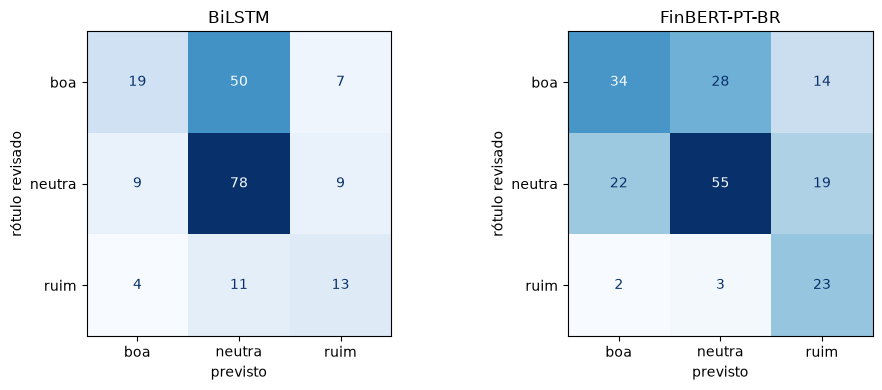

In [11]:
melhor_rede = max(modelos, key=lambda t: comparacao.loc[t, "F1 macro"])
print(f"Melhor rede: {melhor_rede}\n")
print(classification_report(teste["rotulo"], teste[melhor_rede], labels=ROTULOS, digits=3, zero_division=0))

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for ax, nome in zip(eixos, [melhor_rede, "FinBERT-PT-BR"]):
    ConfusionMatrixDisplay.from_predictions(teste["rotulo"], teste[nome], labels=ROTULOS, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nome)
    ax.set_xlabel("previsto")
    ax.set_ylabel("rótulo revisado")
plt.tight_layout()
plt.show()

## Erros

Onde a melhor rede erra e onde ela e o FinBERT discordam.

In [12]:
erros = teste[teste[melhor_rede] != teste["rotulo"]]
print(f"{len(erros)} erros de {len(teste)}\n")
print("Rótulo revisado x previsto nos erros:")
print(erros.groupby(["rotulo", melhor_rede]).size().to_string(), "\n")
erros[["empresa", "manchete", "rotulo", melhor_rede, "FinBERT-PT-BR"]].sample(15, random_state=SEMENTE)

90 erros de 200

Rótulo revisado x previsto nos erros:
rotulo  BiLSTM
boa     neutra    50
        ruim       7
neutra  boa        9
        ruim       9
ruim    boa        4
        neutra    11 



,empresa,manchete,rotulo,BiLSTM,FinBERT-PT-BR
75,ABEV3,"Volumes da Ambev decepcionam durante a Copa, e ações caem",ruim,neutra,ruim
36,ELET3,"Privatização da Eletrobras foi ""maior roubo do país"", diz Lula",ruim,neutra,ruim
110,RENT3,Localiza (RENT3): Goldman corta preço-alvo e aponta riscos para os resultados do 2T26,ruim,neutra,ruim
160,ITUB4,Sem surpresas! Resultado do Itaú (ITUB4) veio em linha com o esperado: é hora de comprar ou vender as ações?,neutra,boa,boa
0,SANB11,"Santander Brasil (SANB11) aprova JCP de R$ 0,40 por unit",boa,neutra,neutra
45,RDOR3,Rede D’Or e BradSaúde mudam de escala em Minas e acirram disputa com Mater Dei e Unimed BH,boa,neutra,ruim
72,WEGE3,WEG (WEGE3) vira uma das melhores geradoras de valor no longo prazo; ações disparam,boa,neutra,boa
140,EQTL3,Equatorial atribui à gestão municipal responsabilidade pela rede do Terminal da Cohab,neutra,ruim,ruim
13,BBDC4,Bradesco Vida e Previdência reforça liderança em Pernambuco durante Roadshow em Recife,boa,neutra,boa
82,B3SA3,"Custo da Bolsa no Brasil pode ser 20 vezes maior do que em outros países, diz CEO da Base Exchange, futura concorren...",ruim,neutra,neutra


In [13]:
so_rede = teste[(teste[melhor_rede] == teste["rotulo"]) & (teste["FinBERT-PT-BR"] != teste["rotulo"])]
so_finbert = teste[(teste[melhor_rede] != teste["rotulo"]) & (teste["FinBERT-PT-BR"] == teste["rotulo"])]
print(f"Só a {melhor_rede} acerta: {len(so_rede)} · Só o FinBERT acerta: {len(so_finbert)}")
pd.concat({f"só {melhor_rede} acerta": so_rede.head(6), "só FinBERT acerta": so_finbert.head(6)})[
    ["manchete", "rotulo", melhor_rede, "FinBERT-PT-BR"]]

Só a BiLSTM acerta: 38 · Só o FinBERT acerta: 40


manchete  \
só BiLSTM acerta  6                                                         Obras da Sabesp provocam nova interdição temporária na Maranduba   
                  16                                                             Rede D'Or (RDOR3) registra acordo de acionistas por 20 anos   
                  17                                      Fim da escala 6×1 deve mudar jornadas da WEG, que incluem 6×2 e “semana espanhola”   
                  21                                                               Itaú Unibanco (ITUB4) emite R$ 5 bi em letras financeiras   
                  31                 Grupo Equatorial lança edital de Eficiência Energética com R$ 61 milhões para financiamento de projetos   
                  35                                                   Banco do Brasil lança novo aplicativo com foco em IA e personalização   
só FinBERT acerta 5               Valor 1000: Sabesp, líder do setor de água, saneamento e serviços ambientais, acelera para antecipar metas   
                  8   JP Morgan 'manda vender' ação do Banco do Brasil (BBAS3) após rali eleitoral — e elege outro bancão para comprar agora   
                  9                                                                  Telefônica Brasil vai incorporar a subsidiária FiBrasil   
                  10                                                                                           Ambev sente a ressaca da Copa   
                  11                             Motociclista morre após colisão com carro de prestadora de serviços da Equatorial em Maceió   
                  13                                  Bradesco Vida e Previdência reforça liderança em Pernambuco durante Roadshow em Recife   

                      rotulo  BiLSTM FinBERT-PT-BR  
só BiLSTM acerta  6   neutra  neutra          ruim  
                  16  neutra  neutra           boa  
                  17  neutra  neutra          ruim  
                  21  neutra  neutra           boa  
                  31  neutra  neutra           boa  
                  35  neutra  neutra           boa  
só FinBERT acerta 5      boa  neutra           boa  
                  8     ruim     boa          ruim  
                  9   neutra     boa        neutra  
                  10    ruim  neutra          ruim  
                  11    ruim  neutra          ruim  
                  13     boa  neutra           boa

### Manchetes escritas por nós

As mesmas do notebook 03, em que o tom da frase e o efeito para o acionista apontam para lados diferentes.

In [14]:
exemplos = pd.DataFrame([
    ("Itaú lucra R$ 12 bilhões no trimestre e supera expectativas", "boa"),
    ("Petrobras anuncia pagamento de R$ 20 bilhões em dividendos", "boa"),
    ("Petrobras reajusta o preço da gasolina nas refinarias", "boa"),
    ("Bradesco é condenado a pagar multa milionária ao Procon", "ruim"),
    ("Ações da Ambev despencam após resultado abaixo do esperado", "ruim"),
    ("Localiza corta 2 mil vagas e fecha lojas para reduzir custos", "boa"),
    ("WEG abre inscrições para programa de estágio", "neutra"),
    ("Vale realiza assembleia de acionistas nesta sexta-feira", "neutra"),
], columns=["manchete", "esperado"])
X_ex = vetorizador(exemplos["manchete"].apply(limpa).to_numpy())
for tipo, modelo in modelos.items():
    probs = modelo.predict(X_ex, verbose=0)
    exemplos[tipo] = [f"{ROTULOS[p.argmax()]} ({p.max():.2f})" for p in probs]
exemplos

,manchete,esperado,BiLSTM,GRU,BiLSTM + ajuste fino
0,Itaú lucra R$ 12 bilhões no trimestre e supera expectativas,boa,boa (0.59),boa (0.50),boa (0.60)
1,Petrobras anuncia pagamento de R$ 20 bilhões em dividendos,boa,neutra (0.63),neutra (0.66),neutra (0.65)
2,Petrobras reajusta o preço da gasolina nas refinarias,boa,ruim (0.45),ruim (0.45),ruim (0.50)
3,Bradesco é condenado a pagar multa milionária ao Procon,ruim,ruim (0.73),ruim (0.91),ruim (0.78)
4,Ações da Ambev despencam após resultado abaixo do esperado,ruim,ruim (0.84),ruim (0.83),ruim (0.86)
5,Localiza corta 2 mil vagas e fecha lojas para reduzir custos,boa,ruim (0.83),ruim (0.89),ruim (0.87)
6,WEG abre inscrições para programa de estágio,neutra,boa (0.57),boa (0.69),boa (0.57)
7,Vale realiza assembleia de acionistas nesta sexta-feira,neutra,neutra (0.50),boa (0.51),neutra (0.51)


## Resultados salvos

In [15]:
colunas = ["id", "empresa", "manchete", "rotulo", "TF-IDF + LR (todas as bases)", *modelos, "FinBERT-PT-BR"]
teste[colunas].to_csv(SAIDA / "resultado_rede_neural.csv", index=False)
comparacao.to_csv(SAIDA / "metricas_sentimento.csv")
print(f"Salvo em {SAIDA / 'resultado_rede_neural.csv'} e {SAIDA / 'metricas_sentimento.csv'}")

Salvo em ..\Entregas\30-10-2026\resultado_rede_neural.csv e ..\Entregas\30-10-2026\metricas_sentimento.csv


## Breve análise

**Resultado.** Nas 200 manchetes revisadas:

| modelo | acurácia | F1 macro |
|---|---|---|
| TF-IDF + LR (só 503 humanos) | 0,39 | 0,36 |
| TF-IDF + LR (todas as bases) | 0,52 | 0,49 |
| BiLSTM | 0,55 | 0,49 |
| GRU | 0,49 | 0,46 |
| BiLSTM + ajuste fino | 0,54 | 0,49 |
| FinBERT-PT-BR (sem treino) | **0,56** | **0,55** |

Nenhum modelo treinado por nós superou o FinBERT. A BiLSTM empatou com a linha de base TF-IDF e foi um pouco melhor que a GRU, provavelmente porque lê a manchete nos dois sentidos.

**O volume de dados importa mais que a arquitetura.** Com só as 503 notícias brasileiras, o TF-IDF fica em 0,36. Com as ~46 mil frases traduzidas, sobe para 0,49. Trocar o TF-IDF por uma BiLSTM, com os mesmos dados, não mudou o F1 macro.

**Sobreajuste e mudança de domínio.** As curvas mostram que a melhor época de validação é a primeira: depois a acurácia de treino sobe (0,56 → 0,77) e a de validação cai. Na validação, que é texto traduzido como o treino, o F1 macro é 0,61. No nosso teste ele cai para 0,49. A diferença vem do domínio: 12% das palavras do teste não existem no vocabulário de treino. A maior parte são nomes de empresas, que não importam para o sentimento, mas também há jargão brasileiro que importa, como "proventos", "OPA" e "rali".

**Onde a rede erra.** A BiLSTM quase não reconhece notícia `boa`: chamou 50 das 76 de `neutra` (revocação de 0,25). Nas 15 manchetes de JCP e dividendos, acertou uma, o mesmo problema do FinBERT. O ajuste fino com as 453 notícias brasileiras de treino não mudou o quadro (0,487 × 0,491): são poucos exemplos e o critério delas (retorno) não é exatamente o nosso (impacto para o acionista). Nas manchetes escritas por nós, a BiLSTM acertou 4 de 8 e também errou o reajuste da gasolina e o corte de vagas.

**Rede e FinBERT erram em lugares diferentes.** Em 38 manchetes só a BiLSTM acerta, quase todas neutras que o FinBERT chamou de `ruim` ou `boa` ("Obras da Sabesp…", "Itaú emite R$ 5 bi em letras financeiras"). Em 40 só o FinBERT acerta, a maioria `ruim` ou `boa`. Isso sugere que combinar os dois, ou ajustar um Transformer no nosso critério, pode ir além dos dois.

**Custo.** A BiLSTM tem 2,7 milhões de parâmetros e treina em ~35 s por época em CPU. O FinBERT tem ~110 milhões de parâmetros e não precisou de treino, mas é ~40 vezes maior para rodar.

**Limitações.** O teste tem 200 manchetes (28 `ruim`), então diferenças de 0,01 a 0,03 no F1 não são conclusivas. A maior parte do treino é tradução automática, com erros de tradução. Os rótulos de referência foram sugeridos por IA e revisados por nós.

**Conclusão e próximo passo.** O gargalo é ter dados rotulados no nosso critério e no nosso domínio, não a arquitetura da rede. Para a etapa de Transformers, a proposta é ajustar o BERTimbau com manchetes brasileiras rotuladas no nosso critério: as ~300 manchetes da amostra de rotulagem que ficaram fora do teste, depois de revisadas. A comparação deve usar o mesmo teste de 200 manchetes.